In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("city_day.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Shape: (29531, 16)

Columns:
Index(['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket'],
      dtype='object')

First 5 rows:


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   City        29531 non-null  object        
 1   Date        29531 non-null  datetime64[ns]
 2   PM2.5       24933 non-null  float64       
 3   PM10        18391 non-null  float64       
 4   NO          25949 non-null  float64       
 5   NO2         25946 non-null  float64       
 6   NOx         25346 non-null  float64       
 7   NH3         19203 non-null  float64       
 8   CO          27472 non-null  float64       
 9   SO2         25677 non-null  float64       
 10  O3          25509 non-null  float64       
 11  Benzene     23908 non-null  float64       
 12  Toluene     21490 non-null  float64       
 13  Xylene      11422 non-null  float64       
 14  AQI         24850 non-null  float64       
 15  AQI_Bucket  24850 non-null  object        
dtype

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

Missing Values:
City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

Duplicate Rows: 0

Statistical Summary:


,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,29531,24933.000000,18391.000000,25949.000000,25946.000000,25346.000000,19203.000000,27472.000000,25677.000000,25509.000000,23908.000000,21490.000000,11422.000000,24850.000000
mean,2018-05-14 05:40:15.807118080,67.450578,118.127103,17.574730,28.560659,32.309123,23.483476,2.248598,14.531977,34.491430,3.280840,8.700972,3.070128,166.463581
min,2015-01-01 00:00:00,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,2017-04-16 00:00:00,28.820000,56.255000,5.630000,11.750000,12.820000,8.580000,0.510000,5.670000,18.860000,0.120000,0.600000,0.140000,81.000000
50%,2018-08-05 00:00:00,48.570000,95.680000,9.890000,21.690000,23.520000,15.850000,0.890000,9.160000,30.840000,1.070000,2.970000,0.980000,118.000000
75%,2019-09-03 00:00:00,80.590000,149.745000,19.950000,37.620000,40.127500,30.020000,1.450000,15.220000,45.570000,3.080000,9.150000,3.350000,208.000000
max,2020-07-01 00:00:00,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000
std,NaN,64.661449,90.605110,22.785846,24.474746,31.646011,25.684275,6.962884,18.133775,21.694928,15.811136,19.969164,6.323247,140.696585


In [ ]:
# Convert Date to date format
df["Date"] = pd.to_datetime(df["Date"])

# Remove rows where AQI is missing
df = df.dropna(subset=["AQI"])

# Fill missing numerical values with median
num_cols = df.select_dtypes(include=np.number).columns

df[num_cols] = df[num_cols].fillna(df[num_cols].median())

print("Cleaned Dataset Shape:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Cleaned Dataset Shape: (24850, 16)

Missing values after cleaning:
City          0
Date          0
PM2.5         0
PM10          0
NO            0
NO2           0
NOx           0
NH3           0
CO            0
SO2           0
O3            0
Benzene       0
Toluene       0
Xylene        0
AQI           0
AQI_Bucket    0
dtype: int64


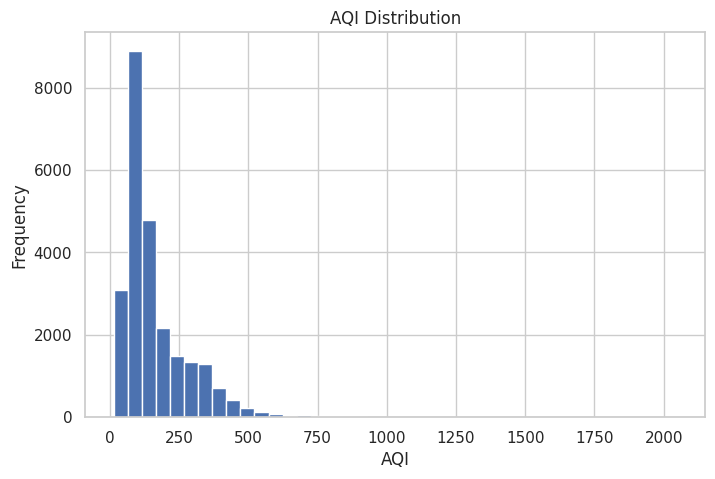

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df["AQI"], bins=40)

plt.title("AQI Distribution")
plt.xlabel("AQI")
plt.ylabel("Frequency")

plt.show()

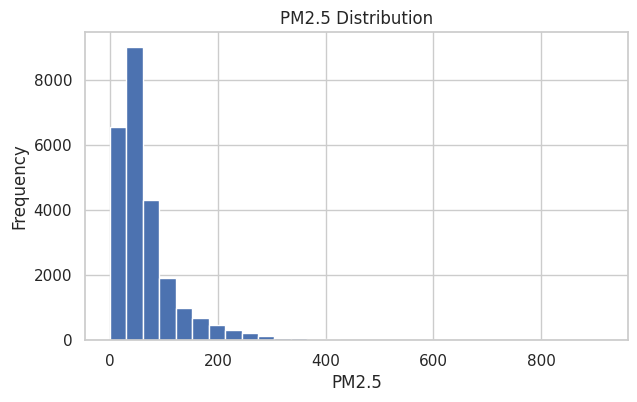

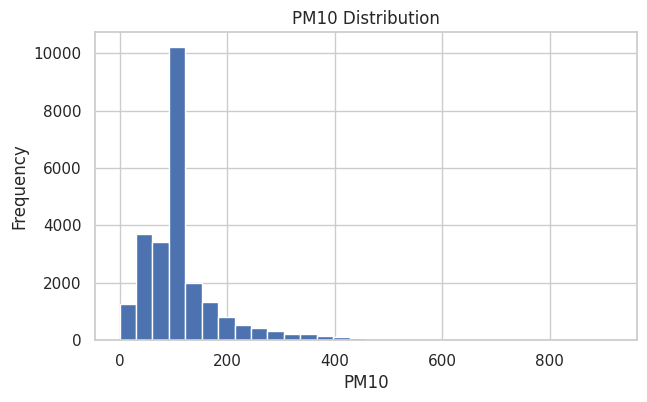

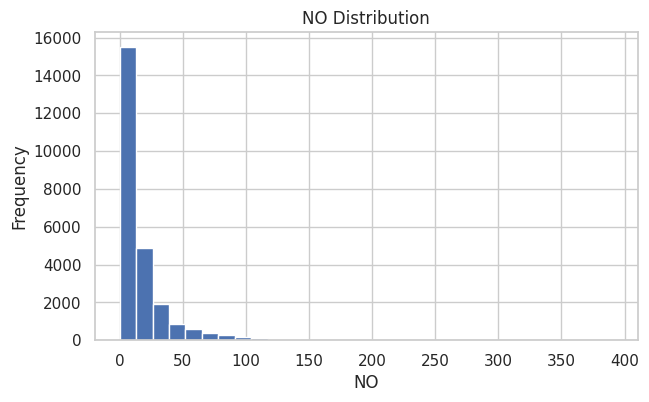

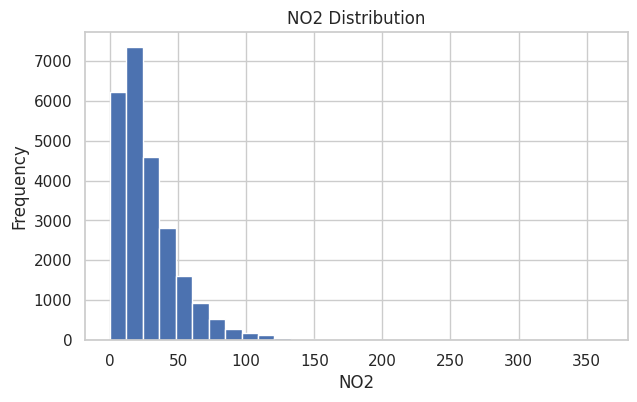

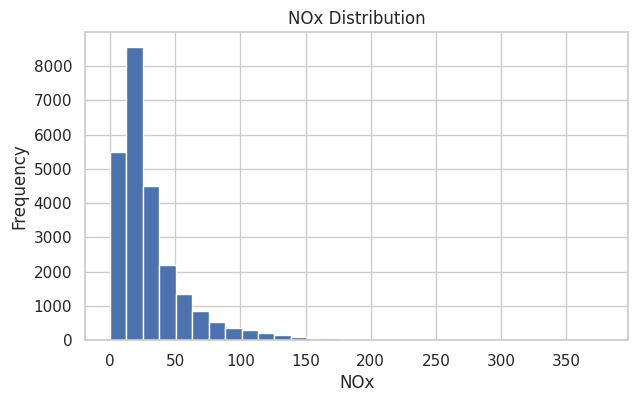

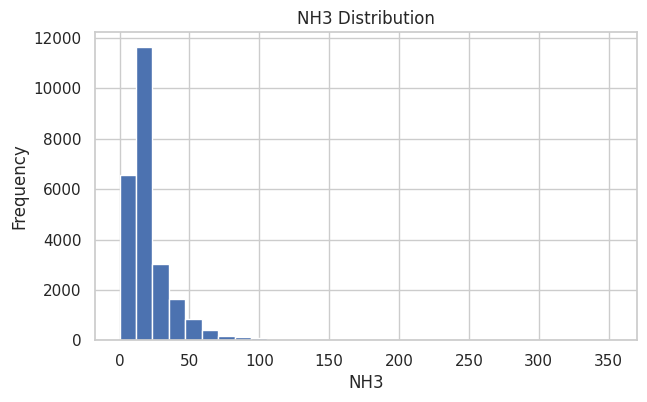

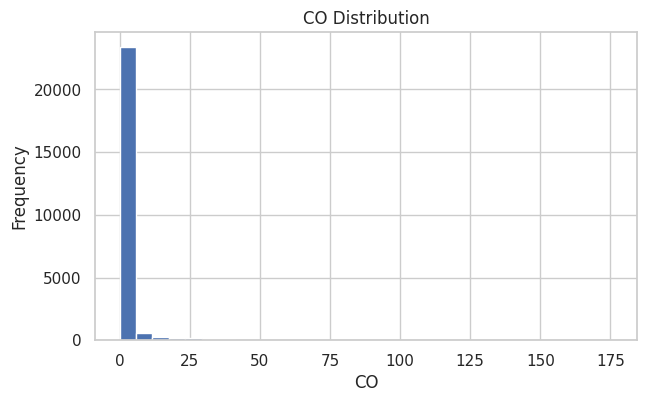

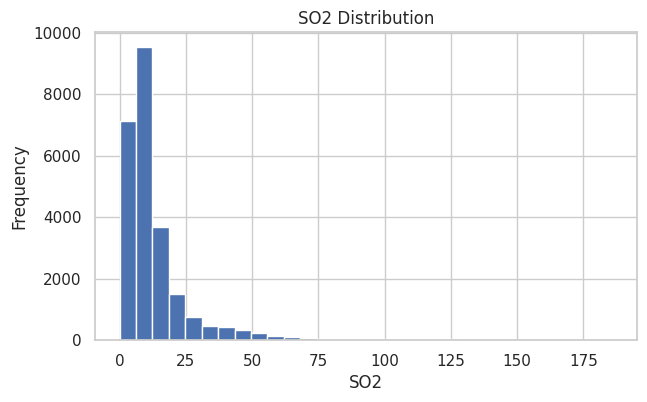

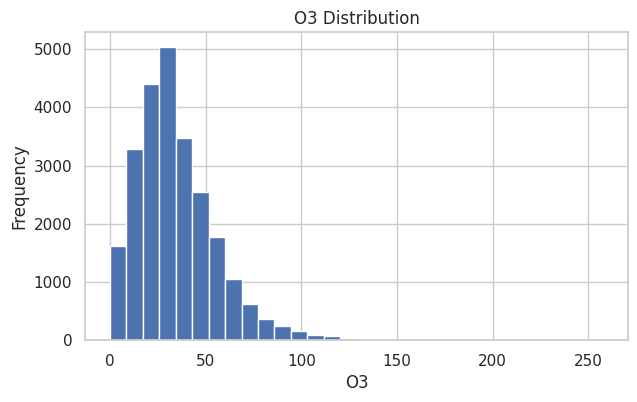

In [ ]:
pollutants = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
              "CO", "SO2", "O3"]

for col in pollutants:
    plt.figure(figsize=(7,4))
    plt.hist(df[col], bins=30)
    plt.title(col + " Distribution")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

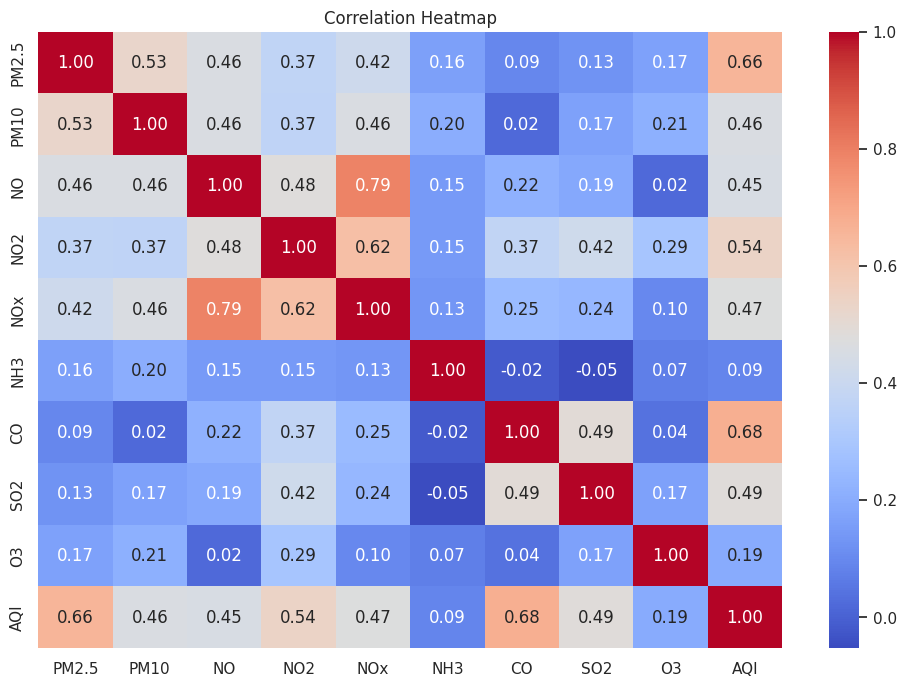

In [ ]:
plt.figure(figsize=(12,8))

corr = df[pollutants + ["AQI"]].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()

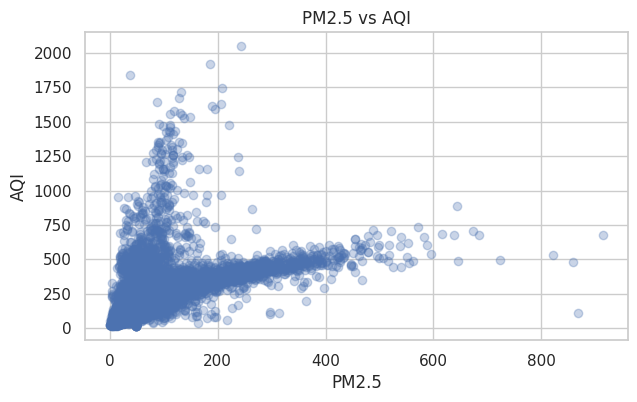

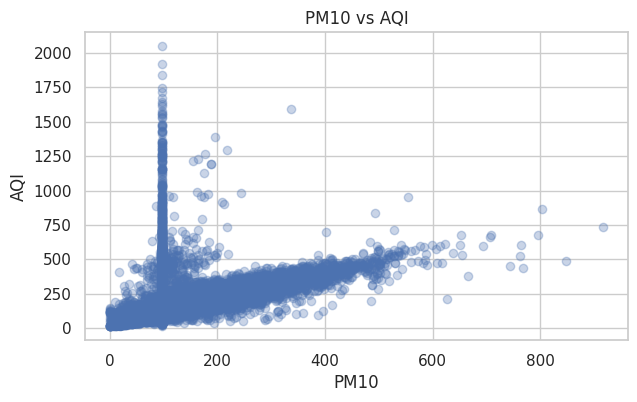

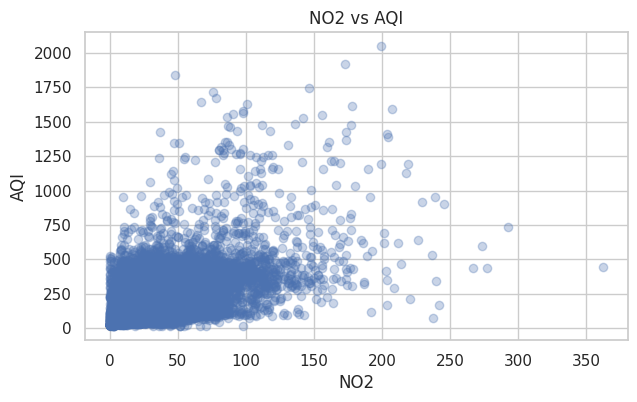

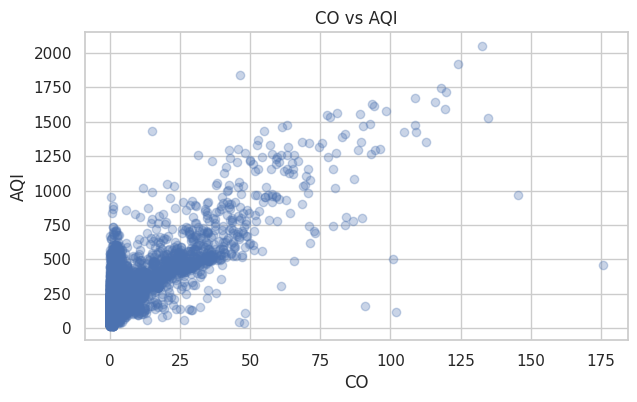

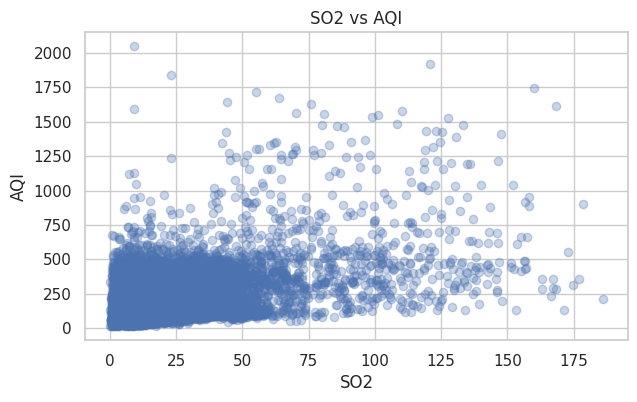

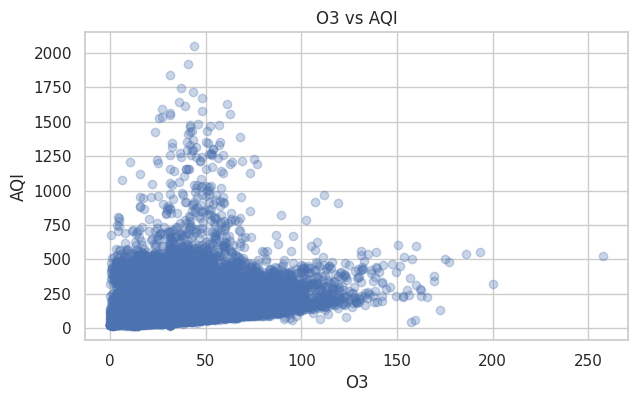

In [ ]:
for col in ["PM2.5", "PM10", "NO2", "CO", "SO2", "O3"]:
    plt.figure(figsize=(7,4))
    plt.scatter(df[col], df["AQI"], alpha=0.3)
    plt.title(col + " vs AQI")
    plt.xlabel(col)
    plt.ylabel("AQI")
    plt.show()

In [7]:
import pandas as pd

df = pd.read_csv('city_day.csv')

print(df.head())
print(df.shape)

        City        Date  PM2.5  PM10     NO    NO2    NOx  NH3     CO    SO2  \
0  Ahmedabad  2015-01-01    NaN   NaN   0.92  18.22  17.15  NaN   0.92  27.64   
1  Ahmedabad  2015-01-02    NaN   NaN   0.97  15.69  16.46  NaN   0.97  24.55   
2  Ahmedabad  2015-01-03    NaN   NaN  17.40  19.30  29.70  NaN  17.40  29.07   
3  Ahmedabad  2015-01-04    NaN   NaN   1.70  18.48  17.97  NaN   1.70  18.59   
4  Ahmedabad  2015-01-05    NaN   NaN  22.10  21.42  37.76  NaN  22.10  39.33   

       O3  Benzene  Toluene  Xylene  AQI AQI_Bucket  
0  133.36     0.00     0.02    0.00  NaN        NaN  
1   34.06     3.68     5.50    3.77  NaN        NaN  
2   30.70     6.80    16.40    2.25  NaN        NaN  
3   36.08     4.43    10.14    1.00  NaN        NaN  
4   39.31     7.01    18.89    2.78  NaN        NaN  
(29531, 16)


In [8]:
numeric_cols = df.select_dtypes(include='number').columns

df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

print("Missing values handled")

Missing values handled


In [9]:
from sklearn.model_selection import train_test_split

features = ['PM2.5', 'PM10', 'NO2', 'NOx', 'NH3',
            'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']

X = df[features]
y = df['AQI']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (23624, 11)
Testing data: (5907, 11)


In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Scaling completed")

Scaling completed


In [11]:
from sklearn.linear_model import Ridge, Lasso

ridge = Ridge(alpha=1.0)
lasso = Lasso(alpha=0.1)

ridge.fit(X_train, y_train)
lasso.fit(X_train, y_train)

ridge_pred = ridge.predict(X_test)
lasso_pred = lasso.predict(X_test)

print("Both models trained successfully")

Both models trained successfully


In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

for name, pred in [('Ridge', ridge_pred), ('Lasso', lasso_pred)]:
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    print("\n", name)
    print("MAE :", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2  :", round(r2, 2))


 Ridge
MAE : 29.87
RMSE: 54.45
R2  : 0.81

 Lasso
MAE : 29.87
RMSE: 54.46
R2  : 0.81


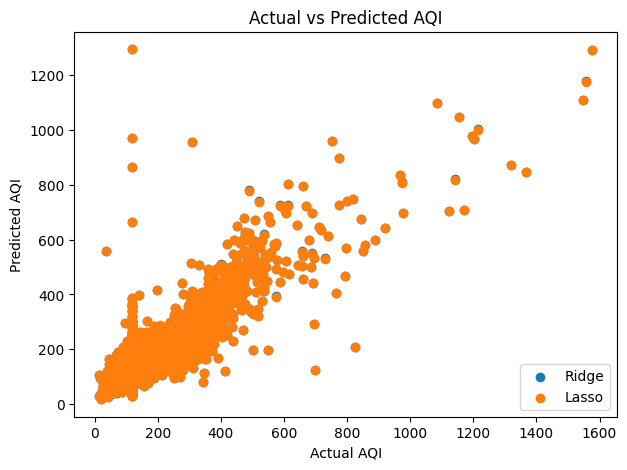

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

plt.scatter(y_test, ridge_pred, label='Ridge')
plt.scatter(y_test, lasso_pred, label='Lasso')

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI")
plt.legend()
plt.show()

In [14]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import r2_score

alphas = [0.01, 0.1, 1, 10, 100]

print("Ridge Results")
for a in alphas:
    model = Ridge(alpha=a)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print("Alpha:", a, "R2:", round(r2_score(y_test, pred), 3))

print("\nLasso Results")
for a in alphas:
    model = Lasso(alpha=a)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print("Alpha:", a, "R2:", round(r2_score(y_test, pred), 3))

Ridge Results
Alpha: 0.01 R2: 0.807
Alpha: 0.1 R2: 0.807
Alpha: 1 R2: 0.807
Alpha: 10 R2: 0.807
Alpha: 100 R2: 0.807

Lasso Results
Alpha: 0.01 R2: 0.807
Alpha: 0.1 R2: 0.807
Alpha: 1 R2: 0.806
Alpha: 10 R2: 0.789
Alpha: 100 R2: -0.0


In [15]:
ridge_final = Ridge(alpha=1)
lasso_final = Lasso(alpha=0.1)

ridge_final.fit(X_train, y_train)
lasso_final.fit(X_train, y_train)

ridge_pred = ridge_final.predict(X_test)
lasso_pred = lasso_final.predict(X_test)

print("Final models trained successfully")

Final models trained successfully


In [16]:
sample = X_test[0].reshape(1, -1)

ridge_result = ridge_final.predict(sample)
lasso_result = lasso_final.predict(sample)

print("Actual AQI:", y_test.iloc[0])
print("Ridge Predicted AQI:", round(ridge_result[0], 2))
print("Lasso Predicted AQI:", round(lasso_result[0], 2))

Actual AQI: 118.0
Ridge Predicted AQI: 110.49
Lasso Predicted AQI: 110.53
